# Batch yeast growth: Monod fit to biomass and glucose

This notebook fits a Monod growth model to the biomass and glucose concentrations measured in one batch reactor. It estimates the maximum specific growth rate $\mu_{max}$ and the observed biomass yield from glucose $Y'_{XS}$, reports 95% confidence intervals from a residual bootstrap, plots the fitted model against the data, and shows how the sum of squared residuals changes as each parameter moves away from its best-fit value.

The model, is

$$\frac{dx}{dt} = \mu x, \qquad \mu = \frac{\mu_{max}\, s}{K_S + s}, \qquad \frac{ds}{dt} = -\frac{1}{Y'_{XS}}\frac{dx}{dt}$$

where $x$ is biomass concentration and $s$ is glucose concentration, both in g/L. $K_S$ is held fixed at the value set below. The initial conditions are the first measured biomass and glucose concentrations.

**To use it:** put your data file in the same folder as this notebook and set the file name in the settings cell. Then choose **Run → Run All Cells** from the menu. The cells depend on one another, so they must run in order from the top; running only a later cell gives a `NameError`. After changing a setting, run all cells again.

In [3]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares

# Some notebook environments running Matplotlib 3.10 print harmless
# "parameter as float was deprecated" warnings when laying out figures.
warnings.filterwarnings("ignore", message=".*parameter as float was deprecated.*")

## 1. Settings

Change only this cell. The data file needs four columns with these exact headers: `timeb (h)` and `biomass (g/L)` for the biomass samples, and `timeg (h)` and `glucose (g/L)` for the glucose samples. The two sets of times do not need to match. Any other columns are ignored.

In [5]:
DATA_FILE = "fermy1.csv"

# Monod saturation constant, held fixed (g/L).
# Doran Table 12.7 lists K_S = 25 mg/L for Saccharomyces cerevisiae on glucose.
K_S = 0.025

# How the two species are weighted in the fit.
#   "range": each species' residuals are divided by the range of its data, so biomass
#            and glucose carry comparable weight even though glucose spans more g/L.
#   "none":  plain residuals in g/L; glucose then dominates the fit.
WEIGHTING = "range"

# Starting guesses for the fit.
MU_MAX_GUESS = 0.3   # 1/h
Y_XS_GUESS = 0.3     # g biomass / g glucose

# Number of bootstrap refits used for the confidence intervals.
# 300 takes up to about a minute; fewer runs faster but gives rougher intervals.
N_BOOT = 300
RANDOM_SEED = 42

## 2. Load the data

In [7]:
if not os.path.exists(DATA_FILE):
    csv_files = sorted(f for f in os.listdir(".") if f.lower().endswith(".csv"))
    raise FileNotFoundError(
        f'Cannot find "{DATA_FILE}" in the folder this notebook is in.\n'
        f"CSV files in this folder: {', '.join(csv_files) if csv_files else 'none'}.\n"
        "Move your data file into this folder, or change DATA_FILE in the settings cell "
        "to match its name exactly."
    )
df = pd.read_csv(DATA_FILE)

biomass_rows = df[["timeb (h)", "biomass (g/L)"]].dropna()
glucose_rows = df[["timeg (h)", "glucose (g/L)"]].dropna()

t_x = biomass_rows["timeb (h)"].to_numpy(dtype=float)
x_data = biomass_rows["biomass (g/L)"].to_numpy(dtype=float)
t_s = glucose_rows["timeg (h)"].to_numpy(dtype=float)
s_data = glucose_rows["glucose (g/L)"].to_numpy(dtype=float)

x0 = x_data[np.argmin(t_x)]
s0 = s_data[np.argmin(t_s)]
t_end = max(t_x.max(), t_s.max())

if WEIGHTING == "range":
    w_x, w_s = np.ptp(x_data), np.ptp(s_data)
elif WEIGHTING == "none":
    w_x, w_s = 1.0, 1.0
else:
    raise ValueError('WEIGHTING must be "range" or "none".')

print(f"{len(t_x)} biomass points from {t_x.min():g} to {t_x.max():g} h")
print(f"{len(t_s)} glucose points from {t_s.min():g} to {t_s.max():g} h")
print(f"Initial conditions: x0 = {x0:.3f} g/L, s0 = {s0:.3f} g/L")

14 biomass points from 0 to 6.5 h
14 glucose points from 0 to 6.5 h
Initial conditions: x0 = 0.250 g/L, s0 = 4.000 g/L


## 3. Model

In [9]:
def monod_batch(t, y, mu_max, Y_XS):
    x, s = y
    s = max(s, 0.0)                 # glucose cannot go negative
    mu = mu_max * s / (K_S + s)
    dxdt = mu * x
    dsdt = -dxdt / Y_XS
    return [dxdt, dsdt]


def glucose_exhausted(t, y, mu_max, Y_XS):
    return y[1] - 1e-6 * s0
glucose_exhausted.terminal = True
glucose_exhausted.direction = -1


def simulate(params):
    # Solves the model once and returns a function that gives (x, s) at any time.
    # Integration stops when glucose is exhausted; after that, growth has stopped,
    # so x stays at its final value and s stays at zero.
    mu_max, Y_XS = params
    sol = solve_ivp(monod_batch, [0.0, t_end], [x0, s0], args=(mu_max, Y_XS),
                    method="LSODA", dense_output=True, rtol=1e-6, atol=1e-9,
                    events=glucose_exhausted)
    if sol.status == -1:
        raise RuntimeError(sol.message)
    t_stop, x_stop = sol.t[-1], sol.y[0, -1]

    def at(t):
        t = np.atleast_1d(np.asarray(t, dtype=float))
        out = np.empty((2, t.size))
        before = t <= t_stop
        out[:, before] = sol.sol(t[before])
        out[0, ~before] = x_stop
        out[1, ~before] = 0.0
        return out

    return at


def residuals(params, x_obs=x_data, s_obs=s_data):
    # Weighted residuals for both species, stacked into one vector.
    model = simulate(params)
    x_model = model(t_x)[0]
    s_model = model(t_s)[1]
    return np.concatenate([(x_model - x_obs) / w_x, (s_model - s_obs) / w_s])


def fit(x_obs=x_data, s_obs=s_data, p0=(MU_MAX_GUESS, Y_XS_GUESS)):
    # diff_step sets the finite-difference step for the Jacobian; it must be much larger
    # than the ODE solver's relative tolerance or the gradient is dominated by solver noise.
    result = least_squares(residuals, p0, args=(x_obs, s_obs),
                           bounds=([1e-4, 1e-4], [5.0, 5.0]), diff_step=1e-3)
    if not result.success:
        raise RuntimeError(result.message)
    return result.x

## 4. Best fit

In [11]:
best = fit()
mu_max_fit, Y_XS_fit = best

model = simulate(best)
x_resid = x_data - model(t_x)[0]      # residual = measured minus model
s_resid = s_data - model(t_s)[1]
ssr_x = np.sum(x_resid**2)
ssr_s = np.sum(s_resid**2)

print(f"mu_max = {mu_max_fit:.3f} 1/h")
print(f"Y'_XS  = {Y_XS_fit:.3f} g/g")
print(f"K_S    = {K_S:g} g/L (fixed)")
print(f"SSR biomass = {ssr_x:.4f} (g/L)^2 over {len(t_x)} points")
print(f"SSR glucose = {ssr_s:.4f} (g/L)^2 over {len(t_s)} points")

mu_max = 0.414 1/h
Y'_XS  = 0.383 g/g
K_S    = 0.025 g/L (fixed)
SSR biomass = 0.0526 (g/L)^2 over 14 points
SSR glucose = 0.4917 (g/L)^2 over 14 points


## 5. Confidence intervals by residual bootstrap

For a simple linear fit, confidence intervals are determined analytically: the standard error of the slope, calculated directly from the residual scatter around the line, is multiplied by a critical $t$-value. Nonlinear models governed by coupled differential equations lack a closed-form formula like this. Instead, parameter uncertainty can be estimated through residual bootstrapping, which computationally simulates repeating your experiment hundreds of times. To generate each synthetic repeat, the notebook takes the smooth best-fit curves and adds a randomly picked residual from your actual run onto each model point. The notebook repeats this process to generate and refit 300 synthetic datasets, and the 95% confidence interval is the spread containing the middle 95% of those 300 fitted values. 

In [13]:
rng = np.random.default_rng(RANDOM_SEED)
x_best, s_best = model(t_x)[0], model(t_s)[1]

boot = []
n_failed = 0
for _ in range(N_BOOT):
    x_synth = x_best + rng.choice(x_resid, size=x_resid.size, replace=True)
    s_synth = s_best + rng.choice(s_resid, size=s_resid.size, replace=True)
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            boot.append(fit(x_synth, s_synth, p0=best))
    except (RuntimeError, ValueError):
        n_failed += 1
boot = np.array(boot)

if n_failed > 0.1 * N_BOOT:
    print(f"Warning: {n_failed} of {N_BOOT} bootstrap fits failed; treat the intervals with caution.")

ci_low, ci_high = np.percentile(boot, [2.5, 97.5], axis=0)
for name, unit, value, lo, hi in zip(["mu_max", "Y'_XS"], ["1/h", "g/g"], best, ci_low, ci_high):
    print(f"{name:7s}= {value:.3f} {unit}   95% CI {lo:.3f} to {hi:.3f}")

mu_max = 0.414 1/h   95% CI 0.398 to 0.414
Y'_XS  = 0.383 g/g   95% CI 0.367 to 0.389


## 6. Model and data

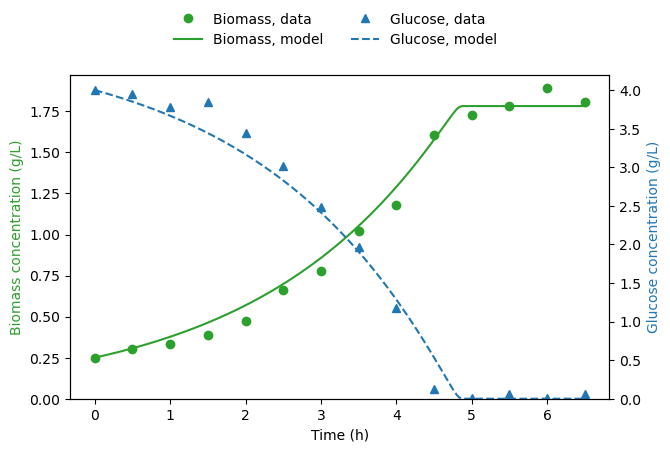

In [15]:
t_smooth = np.linspace(0.0, t_end, 200)
x_smooth, s_smooth = model(t_smooth)

fig, ax_x = plt.subplots(figsize=(7, 4.5))
ax_s = ax_x.twinx()

ax_x.plot(t_x, x_data, "o", color="tab:green", label="Biomass, data")
ax_x.plot(t_smooth, x_smooth, "-", color="tab:green", label="Biomass, model")
ax_s.plot(t_s, s_data, "^", color="tab:blue", label="Glucose, data")
ax_s.plot(t_smooth, s_smooth, "--", color="tab:blue", label="Glucose, model")

ax_x.set_xlabel("Time (h)")
ax_x.set_ylabel("Biomass concentration (g/L)", color="tab:green")
ax_s.set_ylabel("Glucose concentration (g/L)", color="tab:blue")
ax_x.set_ylim(bottom=0)
ax_s.set_ylim(bottom=0)

handles = ax_x.get_legend_handles_labels()[0] + ax_s.get_legend_handles_labels()[0]
labels = ax_x.get_legend_handles_labels()[1] + ax_s.get_legend_handles_labels()[1]
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False)
fig.subplots_adjust(left=0.11, right=0.88, bottom=0.12, top=0.84)
plt.show()

## 7. Sensitivity of the fit to each parameter

Each panel varies one parameter from 50% to 150% of its best-fit value while holding the other at its best-fit value, and plots the weighted sum of squared residuals that the fit minimizes. A sharp minimum means the data pin that parameter down; a flat one means they do not.

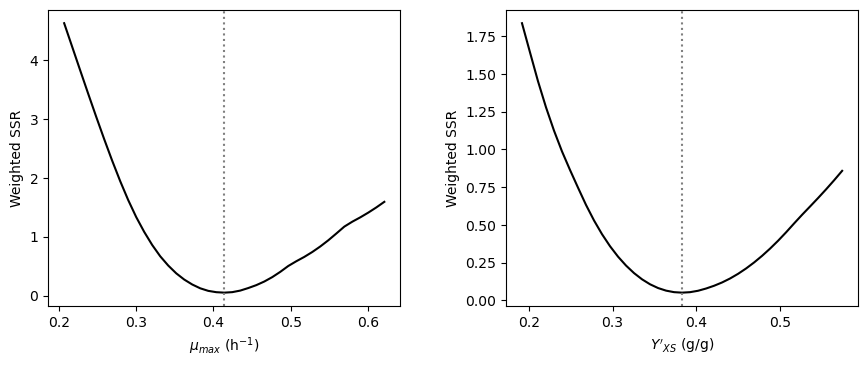

In [23]:
names = [r"$\mu_{max}$ (h$^{-1}$)", r"$Y'_{XS}$ (g/g)"]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))

for i, ax in enumerate(axes):
    values = np.linspace(0.5 * best[i], 1.5 * best[i], 41)
    ssr = []
    for v in values:
        trial = best.copy()
        trial[i] = v
        ssr.append(np.sum(residuals(trial)**2))
    ax.plot(values, ssr, "-", color="black")
    ax.axvline(best[i], color="gray", linestyle=":")
    ax.set_xlabel(names[i])
    ax.set_ylabel("Weighted SSR")

fig.subplots_adjust(left=0.08, right=0.98, bottom=0.17, top=0.95, wspace=0.3)
plt.show()